In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_csv_path = "/content/drive/MyDrive/DataSets/mnist/mnist_train.csv"
test_csv_path  = "/content/drive/MyDrive/DataSets/mnist/mnist_test.csv"

In [ ]:
# Load CSV files
print("Loading training data...")
train_data = pd.read_csv(train_csv_path)
print(f"✓ Training data loaded: {train_data.shape}")

print("Loading test data...")
test_data = pd.read_csv(test_csv_path)
print(f"✓ Test data loaded: {test_data.shape}")

Loading training data...
✓ Training data loaded: (60000, 785)
Loading test data...
✓ Test data loaded: (10000, 785)


STEP 3: EXTRACT LABELS AND PIXELS
# Why: Need to separate labels (first column) from pixel values (784 columns)

In [ ]:
print("\n" + "="*60)
print("EXTRACTING LABELS AND PIXELS")
print("="*60)

# Extract labels (first column)
y_train = train_data.iloc[:, 0].values
y_test = test_data.iloc[:, 0].values

# Extract pixel values (remaining columns)
x_train = train_data.iloc[:, 1:].values
x_test = test_data.iloc[:, 1:].values

print(f"Training samples: {x_train.shape[0]}")
print(f"Test samples: {x_test.shape[0]}")
print(f"Pixels per image: {x_train.shape[1]}")
print(f"Unique labels: {np.unique(y_train)}")


EXTRACTING LABELS AND PIXELS
Training samples: 60000
Test samples: 10000
Pixels per image: 784
Unique labels: [0 1 2 3 4 5 6 7 8 9]


STEP 4: RESHAPE AND PREPROCESS DATA
#CSV gives us flat 784 values, need to reshape to 28x28 image


DATA PREPROCESSING
After reshape - Training: (60000, 28, 28, 1), Test: (10000, 28, 28, 1)
After normalization - Range: [0.00, 1.00]
Label encoding example:
  Original label: 5
  One-hot encoded: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]

Visualizing sample images...


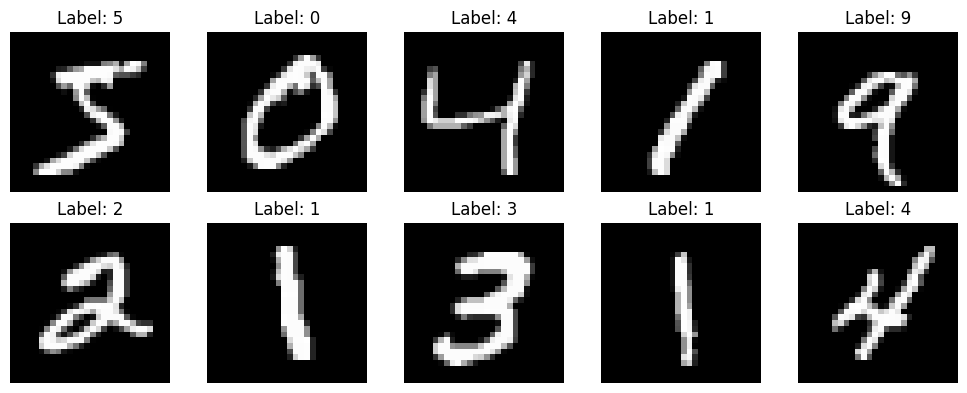

✓ Sample images saved as 'mnist_samples.png'


In [ ]:
print("\n" + "="*60)
print("DATA PREPROCESSING")
print("="*60)

# Step 4.1: Reshape from (784,) to (28, 28, 1)
# Why: CNNs need height x width x channels format
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)
print(f"After reshape - Training: {x_train.shape}, Test: {x_test.shape}")

# Step 4.2: Normalize pixel values to [0, 1]
# Why: Neural networks train better with normalized inputs
# Original range: [0, 255] -> New range: [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print(f"After normalization - Range: [{x_train.min():.2f}, {x_train.max():.2f}]")

# Step 4.3: One-hot encode labels
# Why: Multi-class classification needs categorical format
# Example: Label 3 -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)
print(f"Label encoding example:")
print(f"  Original label: {y_train[0]}")
print(f"  One-hot encoded: {y_train_cat[0]}")

# Visualize sample images
print("\nVisualizing sample images...")
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.savefig('mnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sample images saved as 'mnist_samples.png'")

STEP 5: BUILD CNN MODEL (CONVOLUTIONAL NEURAL NETWORK)
# Why: CNNs are best for image classification
# They automatically learn features like edges, shapes, patterns

In [ ]:
print("\n" + "="*60)
print("BUILDING CNN MODEL")
print("="*60)

def create_cnn_model():
    """
    Create a CNN model for MNIST digit classification

    Architecture explanation:
    - Conv2D: Extract features (edges, curves, shapes)
    - MaxPooling: Reduce size while keeping important features
    - Dropout: Prevent overfitting by randomly dropping neurons during training
    - Dense: Final classification layers
    """

    inputs = tf.keras.Input(shape=(28, 28, 1))

    # BLOCK 1: Learn basic features (edges, simple curves)
    # 32 filters of size 3x3 scan the image
    # ReLU activation: max(0, x) - helps model learn non-linear patterns
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D((2, 2))(x)  # Reduce 28x28 → 14x14
    x = layers.Dropout(0.25)(x)  # Randomly drop 25% of neurons

    # BLOCK 2: Learn complex features (digit shapes, loops, lines)
    # 64 filters - more filters learn more complex patterns
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)  # Reduce 14x14 → 7x7
    x = layers.Dropout(0.25)(x)

    # BLOCK 3: Learn very detailed features (specific digit characteristics)
    # 128 filters for fine details
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.Dropout(0.25)(x)

    # FLATTEN: Convert 2D feature maps to 1D vector for Dense layers
    x = layers.Flatten()(x)

    # DENSE LAYER: Learn combinations of all features
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)  # Higher dropout before output

    # OUTPUT LAYER: 10 neurons (one per digit 0-9)
    # SOFTMAX: Converts outputs to probabilities that sum to 1.0
    outputs = layers.Dense(10, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model


BUILDING CNN MODEL


In [ ]:
# Create the model
model = create_cnn_model()

# KEY CONCEPT: WHY SOFTMAX AND NOT SIGMOID?

In [ ]:
print("\n" + "="*60)
print("ACTIVATION FUNCTIONS - IMPORTANT CONCEPT")
print("="*60)
print("""
MNIST DIGITS PROJECT (Multi-class Classification):
  - 10 classes: Digits 0-9
  - Output layer: 10 neurons with SOFTMAX activation
  - Softmax formula: e^(x_i) / sum(e^(x_j)) for all j
  - Output: 10 probabilities that sum to 1.0
  - Example: [0.01, 0.02, 0.75, 0.05, 0.03, 0.04, 0.02, 0.03, 0.03, 0.02]
             → Digit 2 has 75% probability (most likely prediction)
  - Loss function: categorical_crossentropy

Hidden Layers use ReLU (Rectified Linear Unit):
  - Formula: max(0, x)
  - If input negative → output 0
  - If input positive → output same value
  - Why ReLU? Fast to compute, prevents vanishing gradients
  - Helps deep networks learn effectively
""")


ACTIVATION FUNCTIONS - IMPORTANT CONCEPT

MNIST DIGITS PROJECT (Multi-class Classification):
  - 10 classes: Digits 0-9
  - Output layer: 10 neurons with SOFTMAX activation
  - Softmax formula: e^(x_i) / sum(e^(x_j)) for all j
  - Output: 10 probabilities that sum to 1.0
  - Example: [0.01, 0.02, 0.75, 0.05, 0.03, 0.04, 0.02, 0.03, 0.03, 0.02]
             → Digit 2 has 75% probability (most likely prediction)
  - Loss function: categorical_crossentropy

Hidden Layers use ReLU (Rectified Linear Unit):
  - Formula: max(0, x)
  - If input negative → output 0
  - If input positive → output same value
  - Why ReLU? Fast to compute, prevents vanishing gradients
  - Helps deep networks learn effectively



STEP 6: COMPILE MODEL
# Why: Set up how the model will learn

In [ ]:
print("\n" + "="*60)
print("COMPILING MODEL")
print("="*60)

# Optimizer: Adam - Adaptive learning rate (smart & efficient)
# Loss: categorical_crossentropy - for multi-class classification
#       (NOT binary_crossentropy like cats/dogs project!)
# Metrics: accuracy - percentage of correct predictions

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',  # Different from cats/dogs!
    metrics=['accuracy']
)

# Display model architecture
model.summary()

print("\n✓ Model compiled successfully")
print(f"Total parameters: {model.count_params():,}")


COMPILING MODEL


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896,906 (3.42 MB)

 Trainable params: 896,906 (3.42 MB)

 Non-trainable params: 0 (0.00 B)


✓ Model compiled successfully
Total parameters: 896,906


STEP 7: SETUP CALLBACKS
# Why: Improve training and prevent common problems

In [ ]:
print("\n" + "="*60)
print("SETTING UP TRAINING CALLBACKS")
print("="*60)

# Callback 1: Early Stopping
# What: Stops training if validation loss doesn't improve
# Why: Prevents overfitting and saves time
early_stop = EarlyStopping(
    monitor='val_loss',      # Watch validation loss
    patience=5,              # Wait 5 epochs before stopping
    restore_best_weights=True,  # Go back to best weights
    verbose=1
)

# Callback 2: Reduce Learning Rate on Plateau
# What: Reduces learning rate when learning stalls
# Why: Helps model fine-tune when it gets stuck
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,              # Reduce LR by half
    patience=3,              # Wait 3 epochs
    min_lr=1e-7,
    verbose=1
)

# Callback 3: Model Checkpoint
# What: Saves best model during training
# Why: Don't lose best model if training continues past optimal point
checkpoint = ModelCheckpoint(
    'best_mnist_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

print("✓ Callbacks configured:")
print("  1. Early Stopping (patience=5)")
print("  2. Learning Rate Reduction (factor=0.5)")
print("  3. Model Checkpoint (saves best model)")


SETTING UP TRAINING CALLBACKS
✓ Callbacks configured:
  1. Early Stopping (patience=5)
  2. Learning Rate Reduction (factor=0.5)
  3. Model Checkpoint (saves best model)


# STEP 8: TRAIN THE MODEL

In [ ]:
print("\n" + "="*60)
print("TRAINING MODEL")
print("="*60)

# Training parameters
EPOCHS = 20        # Number of times to go through entire dataset
BATCH_SIZE = 128   # Number of samples per gradient update

print(f"Training configuration:")
print(f"  - Epochs: {EPOCHS}")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Training samples: {len(x_train):,}")
print(f"  - Batches per epoch: {len(x_train)//BATCH_SIZE}")
print("\nStarting training...\n")

history = model.fit(
    x_train, y_train_cat,
    validation_data=(x_test, y_test_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

print("\n✓ Training complete!")


TRAINING MODEL
Training configuration:
  - Epochs: 20
  - Batch size: 128
  - Training samples: 60,000
  - Batches per epoch: 468

Starting training...

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8172 - loss: 0.5663
Epoch 1: val_accuracy improved from -inf to 0.98110, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8174 - loss: 0.5657 - val_accuracy: 0.9811 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 2/20
466/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9692 - loss: 0.1031
Epoch 2: val_accuracy improved from 0.98110 to 0.98890, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9693 - loss: 0.1030 - val_accuracy: 0.9889 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 3/20
465/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9780 - loss: 0.0740
Epoch 3: val_accuracy improved from 0.98890 to 0.99120, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9780 - loss: 0.0740 - val_accuracy: 0.9912 - val_loss: 0.0254 - learning_rate: 0.0010
Epoch 4/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9835 - loss: 0.0557
Epoch 4: val_accuracy did not improve from 0.99120
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9835 - loss: 0.0557 - val_accuracy: 0.9906 - val_loss: 0.0258 - learning_rate: 0.0010
Epoch 5/20
465/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9851 - loss: 0.0508
Epoch 5: val_accuracy improved from 0.99120 to 0.99240, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9851 - loss: 0.0509 - val_accuracy: 0.9924 - val_loss: 0.0222 - learning_rate: 0.0010
Epoch 6/20
461/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9870 - loss: 0.0459
Epoch 6: val_accuracy did not improve from 0.99240
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9870 - loss: 0.0459 - val_accuracy: 0.9923 - val_loss: 0.0213 - learning_rate: 0.0010
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9869 - loss: 0.0427
Epoch 7: val_accuracy improved from 0.99240 to 0.99330, saving model to best_mnist_model.h5


...

469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9907 - loss: 0.0330 - val_accuracy: 0.9944 - val_loss: 0.0167 - learning_rate: 0.0010
Epoch 11/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9910 - loss: 0.0290
Epoch 11: val_accuracy did not improve from 0.99440
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9910 - loss: 0.0290 - val_accuracy: 0.9939 - val_loss: 0.0197 - learning_rate: 0.0010
Epoch 12/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9907 - loss: 0.0281
Epoch 12: val_accuracy did not improve from 0.99440
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9907 - loss: 0.0281 - val_accuracy: 0.9936 - val_loss: 0.0199 - learning_rate: 0.0010
Epoch 13/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9917 - loss: 0.0262
Epoch 13: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 13: val_accuracy did not improve from 0.99440
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9917 - loss: 0.0262 - val_a

469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9938 - loss: 0.0195 - val_accuracy: 0.9945 - val_loss: 0.0156 - learning_rate: 5.0000e-04
Epoch 15/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9941 - loss: 0.0174
Epoch 15: val_accuracy improved from 0.99450 to 0.99500, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9941 - loss: 0.0174 - val_accuracy: 0.9950 - val_loss: 0.0163 - learning_rate: 5.0000e-04
Epoch 16/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9950 - loss: 0.0156
Epoch 16: val_accuracy did not improve from 0.99500
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9950 - loss: 0.0156 - val_accuracy: 0.9948 - val_loss: 0.0168 - learning_rate: 5.0000e-04
Epoch 17/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9951 - loss: 0.0151
Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 17: val_accuracy improved from 0.99500 to 0.99520, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9951 - loss: 0.0151 - val_accuracy: 0.9952 - val_loss: 0.0175 - learning_rate: 5.0000e-04
Epoch 18/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9956 - loss: 0.0129
Epoch 18: val_accuracy did not improve from 0.99520
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9956 - loss: 0.0129 - val_accuracy: 0.9952 - val_loss: 0.0175 - learning_rate: 2.5000e-04
Epoch 19/20
467/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9962 - loss: 0.0127
Epoch 19: val_accuracy improved from 0.99520 to 0.99570, saving model to best_mnist_model.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9962 - loss: 0.0127 - val_accuracy: 0.9957 - val_loss: 0.0172 - learning_rate: 2.5000e-04
Epoch 19: early stopping
Restoring model weights from the end of the best epoch: 14.

✓ Training complete!


# STEP 9: VISUALIZE TRAINING RESULTS


VISUALIZING TRAINING HISTORY


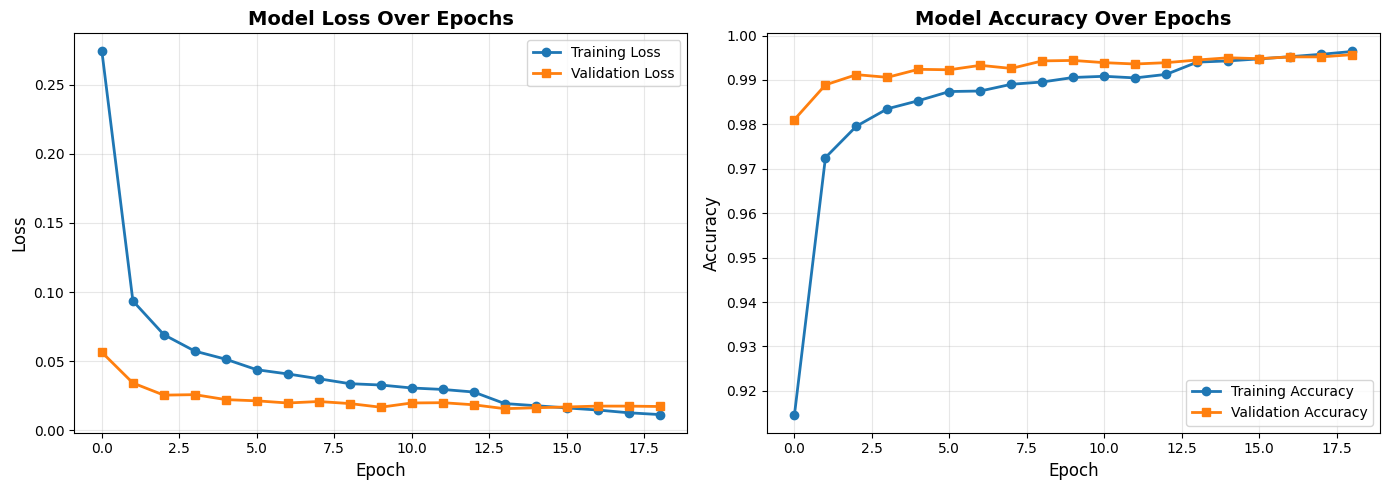

✓ Training plots saved as 'training_history.png'


In [ ]:
print("\n" + "="*60)
print("VISUALIZING TRAINING HISTORY")
print("="*60)

plt.figure(figsize=(14, 5))

# Plot 1: Loss over epochs
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2, marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2, marker='s')
plt.title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

# Plot 2: Accuracy over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2, marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, marker='s')
plt.title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Training plots saved as 'training_history.png'")

# STEP 10: EVALUATE MODEL ON TEST DATA

In [ ]:
print("\n" + "="*60)
print("MODEL EVALUATION")
print("="*60)

test_loss, test_accuracy = model.evaluate(x_test, y_test_cat, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

if test_accuracy > 0.98:
    print("🎉 Excellent! Model performs very well!")
elif test_accuracy > 0.95:
    print("✓ Good performance!")
elif test_accuracy > 0.90:
    print("⚠️ Decent, but could be improved")
else:
    print("❌ Poor performance - check troubleshooting guide")


MODEL EVALUATION
Test Loss: 0.0156
Test Accuracy: 0.9945 (99.45%)
🎉 Excellent! Model performs very well!


# STEP 11: MAKE PREDICTIONS AND VISUALIZE


MAKING PREDICTIONS


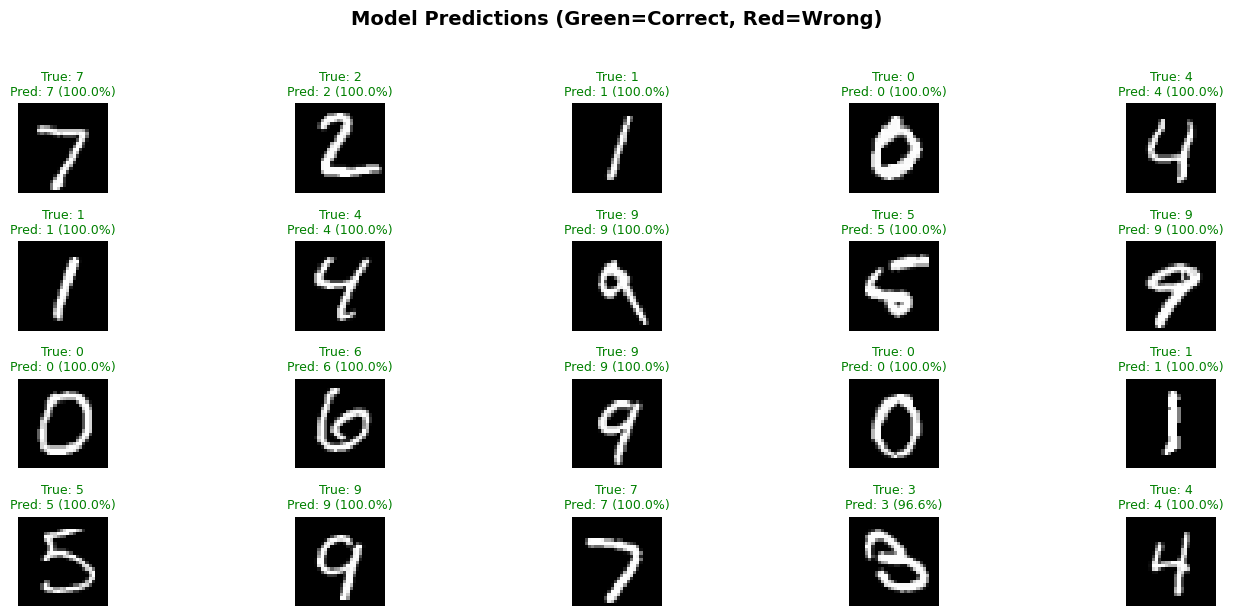

✓ Predictions saved as 'predictions.png'


In [ ]:
print("\n" + "="*60)
print("MAKING PREDICTIONS")
print("="*60)

# Predict on first 20 test images
predictions = model.predict(x_test[:20], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)
true_labels = y_test[:20]

# Calculate confidence scores
confidences = np.max(predictions, axis=1)

# Visualize predictions
plt.figure(figsize=(15, 6))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    # Green if correct, red if wrong
    is_correct = predicted_labels[i] == true_labels[i]
    color = 'green' if is_correct else 'red'

    plt.title(f"True: {true_labels[i]}\nPred: {predicted_labels[i]} ({confidences[i]:.1%})",
              color=color, fontsize=9)
    plt.axis('off')

plt.suptitle('Model Predictions (Green=Correct, Red=Wrong)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Predictions saved as 'predictions.png'")

# STEP 12: CONFUSION MATRIX


CONFUSION MATRIX ANALYSIS


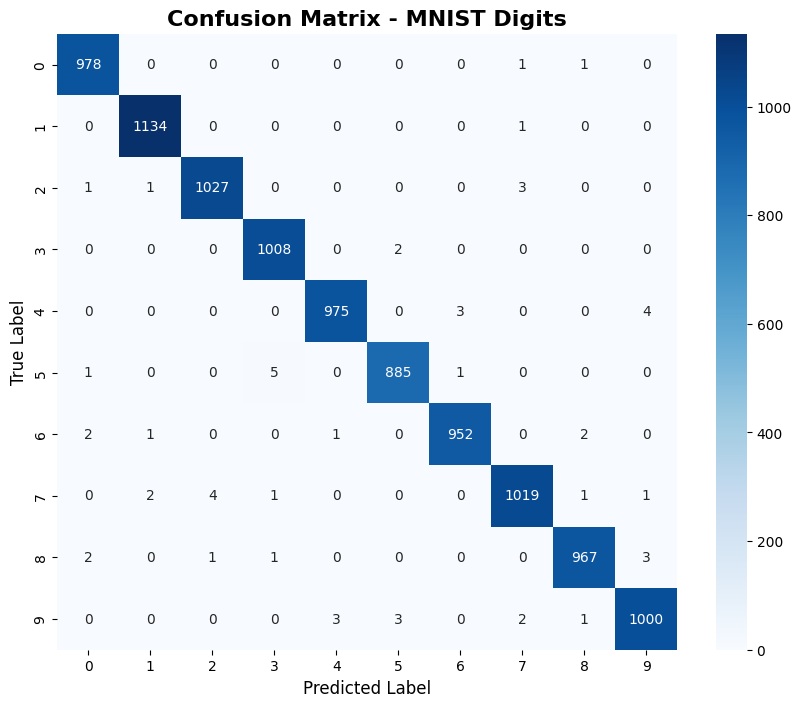

✓ Confusion matrix saved as 'confusion_matrix.png'

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       1.00      1.00      1.00      1135
           2       1.00      1.00      1.00      1032
           3       0.99      1.00      1.00      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [ ]:
print("\n" + "="*60)
print("CONFUSION MATRIX ANALYSIS")
print("="*60)

# Get predictions for all test data
all_predictions = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(all_predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, predicted_classes)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix - MNIST Digits', fontsize=16, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Confusion matrix saved as 'confusion_matrix.png'")

# Print detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(y_test, predicted_classes,
                          target_names=[str(i) for i in range(10)]))

# STEP 13: ANALYZE MISCLASSIFIED EXAMPLES


ANALYZING ERRORS
Total misclassified: 55 out of 10000
Error rate: 0.55%


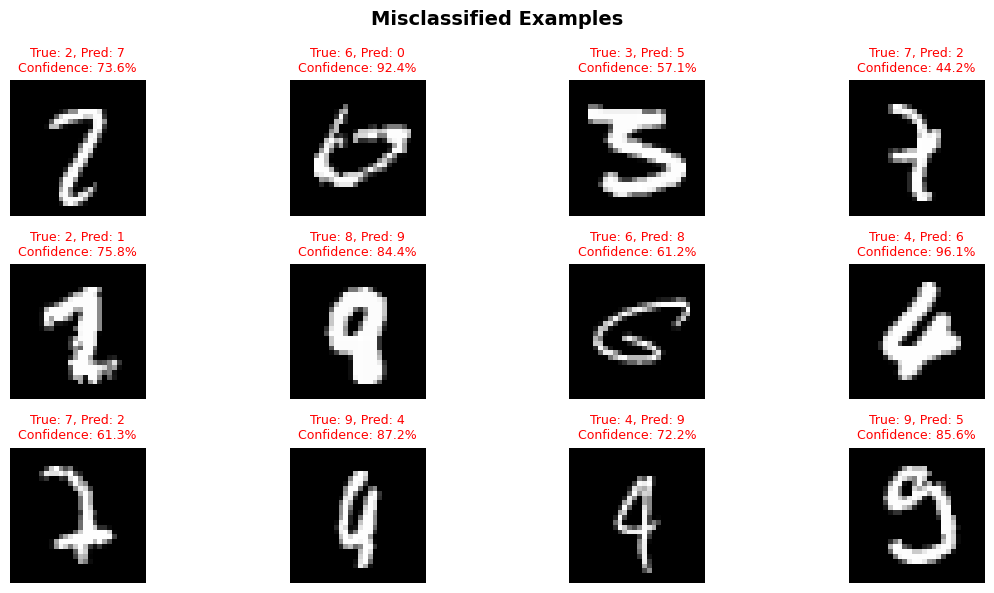

✓ Error analysis saved as 'errors.png'


In [ ]:
print("\n" + "="*60)
print("ANALYZING ERRORS")
print("="*60)

# Find misclassified images
wrong_indices = np.where(predicted_classes != y_test)[0]
print(f"Total misclassified: {len(wrong_indices)} out of {len(y_test)}")
print(f"Error rate: {len(wrong_indices)/len(y_test)*100:.2f}%")

if len(wrong_indices) > 0:
    # Show first 12 misclassified examples
    n_show = min(12, len(wrong_indices))
    plt.figure(figsize=(12, 6))

    for i in range(n_show):
        idx = wrong_indices[i]
        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f"True: {y_test[idx]}, Pred: {predicted_classes[idx]}\n"
                 f"Confidence: {np.max(all_predictions[idx]):.1%}",
                 color='red', fontsize=9)
        plt.axis('off')

    plt.suptitle('Misclassified Examples', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('errors.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Error analysis saved as 'errors.png'")

STEP 14: SAVE FINAL MODEL

In [ ]:
print("\n" + "="*60)
print("SAVING MODEL")
print("="*60)

model.save('mnist_digit_classifier_final.h5')
print("✓ Model saved as 'mnist_digit_classifier_final.h5'")



SAVING MODEL
✓ Model saved as 'mnist_digit_classifier_final.h5'


# STEP 15: TEST INFERENCE FUNCTION


In [ ]:
print("\n" + "="*60)
print("CREATING INFERENCE FUNCTION")
print("="*60)

def predict_digit(model, image_array):
    """
    Predict digit from a single image

    Args:
        model: Trained Keras model
        image_array: 28x28 numpy array

    Returns:
        Dictionary with prediction results
    """
    # Reshape and normalize
    if len(image_array.shape) == 2:
        image_array = image_array.reshape(1, 28, 28, 1)
    image_array = image_array.astype('float32') / 255.0

    # Predict
    prediction = model.predict(image_array, verbose=0)
    predicted_digit = np.argmax(prediction[0])
    confidence = np.max(prediction[0])

    return {
        'digit': int(predicted_digit),
        'confidence': float(confidence),
        'probabilities': prediction[0].tolist()
    }

# Test inference function
test_image = x_test[0] * 255.0  # Denormalize
result = predict_digit(model, test_image.reshape(28, 28))
print(f"Test inference:")
print(f"  Predicted digit: {result['digit']}")
print(f"  Confidence: {result['confidence']:.2%}")
print(f"  True label: {y_test[0]}")


CREATING INFERENCE FUNCTION
Test inference:
  Predicted digit: 7
  Confidence: 100.00%
  True label: 7


# PROJECT COMPLETE!


In [ ]:
print("\n" + "="*60)
print("PROJECT COMPLETE! 🎉")
print("="*60)
print(f"\nFinal Results:")
print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
print(f"  Test Loss: {test_loss:.4f}")
print(f"  Total Parameters: {model.count_params():,}")

print("\nGenerated Files:")
print("  1. mnist_samples.png - Sample training images")
print("  2. training_history.png - Training metrics over epochs")
print("  3. predictions.png - Model predictions visualization")
print("  4. confusion_matrix.png - Confusion matrix heatmap")
print("  5. errors.png - Misclassified examples analysis")
print("  6. best_mnist_model.h5 - Best model (saved during training)")
print("  7. mnist_digit_classifier_final.h5 - Final trained model")

print("\n" + "="*60)
print("Next Steps:")
print("  1. Review confusion matrix to see which digits are confused")
print("  2. Check error examples to understand misclassifications")
print("  3. Try the troubleshooting guide if accuracy < 98%")
print("  4. Use the saved model for predictions on new images")
print("="*60)


PROJECT COMPLETE! 🎉

Final Results:
  Test Accuracy: 99.45%
  Test Loss: 0.0156
  Total Parameters: 896,906

Generated Files:
  1. mnist_samples.png - Sample training images
  2. training_history.png - Training metrics over epochs
  3. predictions.png - Model predictions visualization
  4. confusion_matrix.png - Confusion matrix heatmap
  5. errors.png - Misclassified examples analysis
  6. best_mnist_model.h5 - Best model (saved during training)
  7. mnist_digit_classifier_final.h5 - Final trained model

Next Steps:
  1. Review confusion matrix to see which digits are confused
  2. Check error examples to understand misclassifications
  3. Try the troubleshooting guide if accuracy < 98%
  4. Use the saved model for predictions on new images
